# Overview
> **Chuyển đổi từ `2. CNN + MLP/1_MNIST_CNN.ipynb` sang PyTorch**
- Kiến trúc 3 khối Conv2d(64 -> 128 -> 256) + MaxPool2d(2) + Dropout2d(0.2) + FC(512 -> 512 -> 10)
- Trực quan hóa PCA 2D trên dữ liệu thô, `fc2`, và `GlobalAveragePooling(pool3)` giống bản Keras gốc.


In [1]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# (1) Data (Real MNIST - NCHW format)


In [2]:
with np.load(Path('../../data/mnist.npz')) as f:
    x_train, y_train = f['x_train'], f['y_train']
    x_test, y_test = f['x_test'], f['y_test']

n_tr = 12000 if torch.cuda.is_available() else 4000
n_te = 2000 if torch.cuda.is_available() else 800
x_train = (x_train[:n_tr].astype('float32') / 255.0).reshape(-1, 1, 28, 28)
y_train = y_train[:n_tr].astype(np.int64)
x_test = (x_test[:n_te].astype('float32') / 255.0).reshape(-1, 1, 28, 28)
y_test = y_test[:n_te].astype(np.int64)

train_loader = DataLoader(TensorDataset(torch.tensor(x_train), torch.tensor(y_train)), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.tensor(x_test), torch.tensor(y_test)), batch_size=256, shuffle=False)
print('x_train NCHW:', x_train.shape, '| x_test NCHW:', x_test.shape)


x_train NCHW: (4000, 1, 28, 28) | x_test NCHW: (800, 1, 28, 28)


# (2) Declare model (`MNIST_CNN` 3 Blocks)


In [3]:
class MNIST_CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2)
        )
        self.fc1 = nn.Sequential(nn.Flatten(), nn.Linear(256 * 3 * 3, 512), nn.ReLU(), nn.Dropout(0.2))
        self.fc2 = nn.Sequential(nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.2))
        self.head = nn.Linear(512, num_classes)

    def forward(self, x, return_features=False):
        pool3 = self.features(x)
        fc2_out = self.fc2(self.fc1(pool3))
        logits = self.head(fc2_out)
        if return_features:
            return logits, fc2_out, pool3.mean(dim=(2, 3))
        return logits

model = MNIST_CNN().to(device)
print(model)
print('Params:', sum(p.numel() for p in model.parameters() if p.requires_grad))


MNIST_CNN(
  (features): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout2d(p=0.2, inplace=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.2, inplace=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout2d(p=0.2, inplace=False)
  )
  (fc1): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2304, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
  )
  (fc2): Sequential(
    (0): Linear(in_features=512, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2,

# (3) Train defined model


In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 8 if torch.cuda.is_available() else 5
t0 = time.time()
for epoch in range(1, epochs + 1):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
    model.eval()
    correct, tot_loss = 0, 0.0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            tot_loss += criterion(out, yb).item() * len(xb)
            correct += (out.argmax(1) == yb).sum().item()
    print(f'Epoch {epoch:02d}/{epochs} | Test Loss: {tot_loss/len(x_test):.4f} | Test Acc: {correct/len(x_test)*100:.2f}%')
print('Training time: %.2f s' % (time.time() - t0))


Epoch 01/5 | Test Loss: 0.6450 | Test Acc: 79.75%


Epoch 02/5 | Test Loss: 0.2273 | Test Acc: 91.75%


Epoch 03/5 | Test Loss: 0.1745 | Test Acc: 93.75%


Epoch 04/5 | Test Loss: 0.1502 | Test Acc: 94.62%


Epoch 05/5 | Test Loss: 0.0961 | Test Acc: 96.38%
Training time: 37.74 s


# (4) Evaluate & PCA Feature Visualization (Raw vs `fc2` vs `GAP(pool3)`)


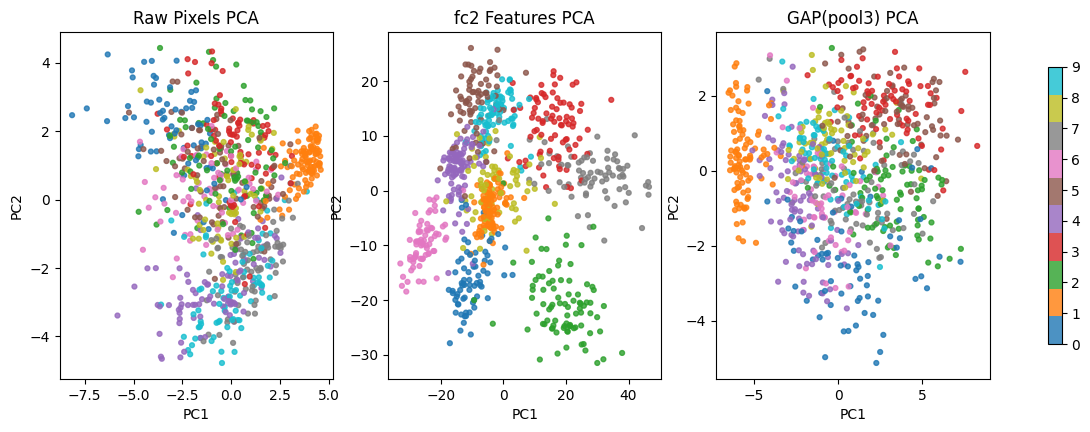

In [5]:
def pca_2d(X):
    Xc = X - X.mean(axis=0, keepdims=True)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Xc @ Vt[:2].T

n_vis = min(1000, len(x_test))
model.eval()
with torch.no_grad():
    x_vis = torch.tensor(x_test[:n_vis]).to(device)
    y_vis = y_test[:n_vis]
    logits, fc2_feat, gap_feat = model(x_vis, return_features=True)

pca_raw = pca_2d(x_test[:n_vis].reshape(n_vis, -1))
pca_fc2 = pca_2d(fc2_feat.cpu().numpy())
pca_gap = pca_2d(gap_feat.cpu().numpy())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, proj, title in zip(axes, [pca_raw, pca_fc2, pca_gap], ['Raw Pixels PCA', 'fc2 Features PCA', 'GAP(pool3) PCA']):
    sc = ax.scatter(proj[:, 0], proj[:, 1], c=y_vis, cmap='tab10', s=12, alpha=0.8)
    ax.set_title(title); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.8)
plt.show()
